### Startup Success Prediction - Pre-Processing

#### Imports

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

#### Reading Data

In [2]:
df = pd.read_csv("../data/startup_success_raw.csv")

df

,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million,investor_type,sector,founder_background,outcome
0,4,13,58,48.225483,594843,18.519211,1.483962e+06,tier2_vc,Health,academic,IPO
1,1,6,221,31.532647,393020,14.298149,8.620568e+05,tier2_vc,Fintech,first_time,Failure
2,3,5,247,4.969722,27636,20.447567,9.726169e+04,none,SaaS,first_time,Failure
3,3,14,229,3.084209,235376,8.177417,1.145785e+06,none,Ecommerce,ex_bigtech,Acquisition
4,1,17,235,13.818188,391765,4.879792,8.608949e+05,none,Health,first_time,Acquisition
...,...,...,...,...,...,...,...,...,...,...,...
99995,1,10,189,38.766348,261932,7.945616,1.005687e+06,tier1_vc,Ecommerce,serial_founder,Failure
99996,1,15,39,49.983039,355153,93.223490,1.627273e+06,none,AI,first_time,Acquisition
99997,0,22,215,3.086470,606292,12.832589,1.967245e+06,tier1_vc,Health,academic,Failure
99998,4,24,231,10.815435,277717,28.205609,2.757053e+05,angel,Crypto,ex_bigtech,Failure


### EDA

In [3]:
df.dtypes

funding_rounds                int64
founder_experience_years      int64
team_size                     int64
market_size_billion         float64
product_traction_users        int64
burn_rate_million           float64
revenue_million             float64
investor_type                   str
sector                          str
founder_background              str
outcome                         str
dtype: object

In [4]:
df.describe()

,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million
count,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,100000.000000,1.000000e+05
mean,2.002300,12.024300,150.732000,33.203875,285422.832730,16.776213,7.828191e+05
std,1.414671,7.208089,86.272631,43.034753,159323.885405,15.711368,6.085069e+05
min,0.000000,0.000000,2.000000,0.288738,668.000000,0.279763,1.344810e+03
25%,1.000000,6.000000,76.000000,10.196778,161194.750000,7.087591,3.154861e+05
50%,2.000000,12.000000,151.000000,20.158063,264989.500000,12.169059,6.213624e+05
75%,3.000000,18.000000,226.000000,39.531967,389214.000000,20.953561,1.098921e+06
max,8.000000,24.000000,299.000000,1072.434476,915203.000000,357.491454,4.168443e+06


#### Checking NULL Values

In [5]:
df.isna().sum()

funding_rounds              0
founder_experience_years    0
team_size                   0
market_size_billion         0
product_traction_users      0
burn_rate_million           0
revenue_million             0
investor_type               0
sector                      0
founder_background          0
outcome                     0
dtype: int64

#### Seperating Success & Failure Outcomes

In [6]:
df['outcome'] = df['outcome'].apply(
    lambda x: 'success' if x in ['IPO','Acquisition'] else 'failure'
)

df['outcome'].value_counts()

outcome
failure    55610
success    44390
Name: count, dtype: int64

### Outlier Analysis

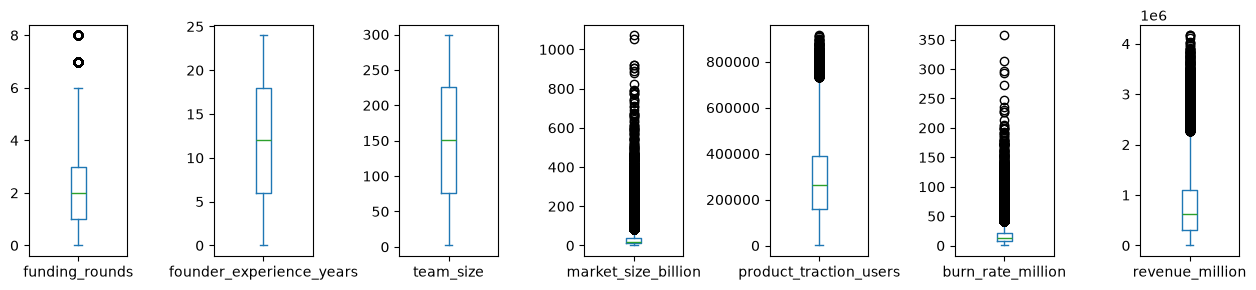

In [7]:
df.plot(kind="box",subplots=True,layout=(1,11),figsize=(20,3))
plt.tight_layout()

#### IQR Method

In [8]:
outlier_columns = ['funding_rounds','market_size_billion','product_traction_users','burn_rate_million','revenue_million']

for col in outlier_columns:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    minimum = q1 - (1.5 * iqr)
    maximum = q3 + (1.5 * iqr)
    df[col] = df[col].clip(minimum,maximum)

df

,funding_rounds,founder_experience_years,team_size,market_size_billion,product_traction_users,burn_rate_million,revenue_million,investor_type,sector,founder_background,outcome
0,4,13,58,48.225483,594843.0,18.519211,1.483962e+06,tier2_vc,Health,academic,success
1,1,6,221,31.532647,393020.0,14.298149,8.620568e+05,tier2_vc,Fintech,first_time,failure
2,3,5,247,4.969722,27636.0,20.447567,9.726169e+04,none,SaaS,first_time,failure
3,3,14,229,3.084209,235376.0,8.177417,1.145785e+06,none,Ecommerce,ex_bigtech,success
4,1,17,235,13.818188,391765.0,4.879792,8.608949e+05,none,Health,first_time,success
...,...,...,...,...,...,...,...,...,...,...,...
99995,1,10,189,38.766348,261932.0,7.945616,1.005687e+06,tier1_vc,Ecommerce,serial_founder,failure
99996,1,15,39,49.983039,355153.0,41.752516,1.627273e+06,none,AI,first_time,success
99997,0,22,215,3.086470,606292.0,12.832589,1.967245e+06,tier1_vc,Health,academic,failure
99998,4,24,231,10.815435,277717.0,28.205609,2.757053e+05,angel,Crypto,ex_bigtech,failure


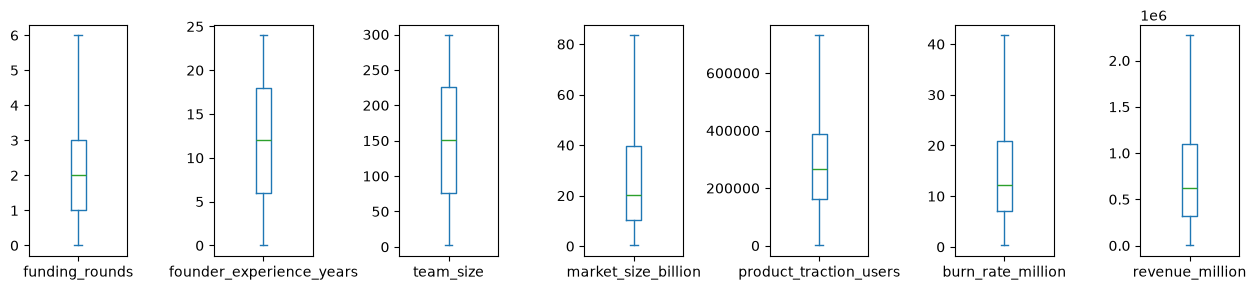

In [9]:
df.plot(kind="box",subplots=True,layout=(1,11),figsize=(20,3))
plt.tight_layout()

### Encoding

In [10]:
categorical_columns = [col for col in df.columns if df[col].dtypes == 'str']

categorical_columns

['investor_type', 'sector', 'founder_background', 'outcome']

In [11]:
for col in categorical_columns:
    df[col] = df[col].astype('category')

df.dtypes

funding_rounds                 int64
founder_experience_years       int64
team_size                      int64
market_size_billion          float64
product_traction_users       float64
burn_rate_million            float64
revenue_million              float64
investor_type               category
sector                      category
founder_background          category
outcome                     category
dtype: object

### Exporting Cleaned Dataset

In [12]:
df.to_csv('../data/startup_success_cleaned.csv', index=False)